# Дополнительный ноутбук 3. Региональные различия потепления (штаты и области)

**Файл:** `GlobalLandTemperaturesByState.csv` — среднемесячные температуры по штатам и областям 7 стран (Россия, США, Индия, Китай, Канада, Бразилия, Австралия). Период наблюдений различается по регионам: самые ранние ряды начинаются в 1743 г., основная масса — в середине XIX века.

**Задача:** сравнить среднюю скорость потепления регионов по странам и найти регионы России, где температура растёт быстрее всего.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True

DATA_DIR = '../data'


In [2]:
st = pd.read_csv(f'{DATA_DIR}/GlobalLandTemperaturesByState.csv',
                 usecols=['dt', 'AverageTemperature', 'State', 'Country'])
st['dt'] = pd.to_datetime(st['dt'])

print(f'Наблюдений: {len(st):,}')
print(f'Регионов: {st["State"].nunique()}, стран: {st["Country"].nunique()}')
print(f'Период: {st["dt"].min().date()} — {st["dt"].max().date()}')
print('\nНаблюдений по странам:')
print(st['Country'].value_counts())

Наблюдений: 645,675
Регионов: 241, стран: 7
Период: 1743-11-01 — 2013-09-01

Наблюдений по странам:
Country
Russia           254972
United States    149745
India             86664
China             68506
Canada            35358
Brazil            34328
Australia         16102
Name: count, dtype: int64


## Средняя скорость потепления регионов по странам

Считаем линейный тренд годовых средних (°C за 100 лет, период с 1900 года) для каждого региона и усредняем по странам.

In [3]:
def slope_per_century(series):
    """Линейный тренд ряда (индекс — годы) в °C за 100 лет."""
    s = series.dropna()
    x = s.index.values.astype(float)
    return np.polyfit(x - x.mean(), s.values, 1)[0] * 100

# Годовые средние: страна -> регион -> год
st_ann = st.groupby(['Country', 'State', st['dt'].dt.year])['AverageTemperature'].mean()

country_trends = {}
region_trends = {}
for country in st_ann.index.get_level_values(0).unique():
    sub = st_ann.loc[country]
    trends = []
    for region in sub.index.get_level_values(0).unique():
        s = sub.loc[region].loc[1900:]
        if s.dropna().shape[0] >= 80:
            t = slope_per_century(s)
            trends.append(t)
            region_trends[(country, region)] = t
    country_trends[country] = np.mean(trends)

country_trends = pd.Series(country_trends).sort_values()
country_trends.round(2)

India            0.81
Australia        0.87
United States    0.98
Brazil           1.00
China            1.08
Canada           1.45
Russia           1.59
dtype: float64

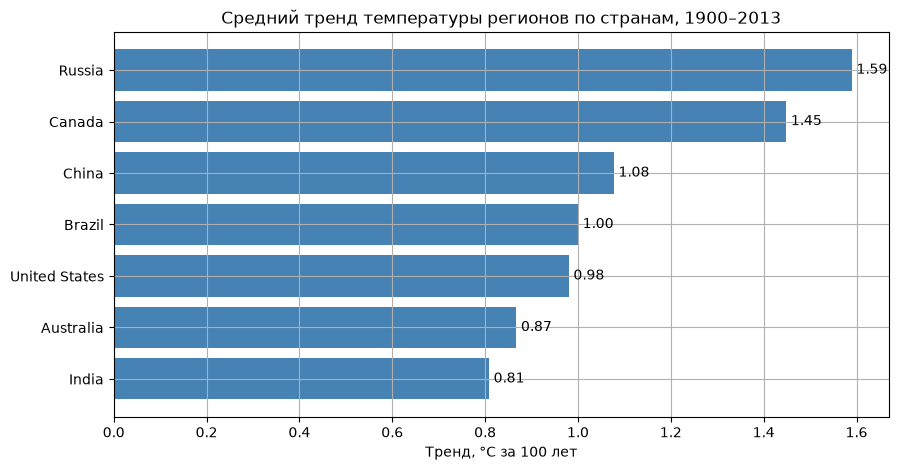

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(country_trends.index, country_trends.values, color='steelblue')
ax.set_title('Средний тренд температуры регионов по странам, 1900–2013')
ax.set_xlabel('Тренд, °C за 100 лет')
for i, v in enumerate(country_trends.values):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
plt.show()

Лидируют Россия (+1.59 °C/100 лет) и Канада (+1.45) — страны с большой долей высокоширотных и континентальных территорий. Это согласуется с известным эффектом **усиленного потепления высоких широт** (polar amplification): таяние снега и льда снижает отражательную способность поверхности, и регион нагревается быстрее.

## Регионы России с самым быстрым потеплением

Регионов России с оценкой тренда: 89


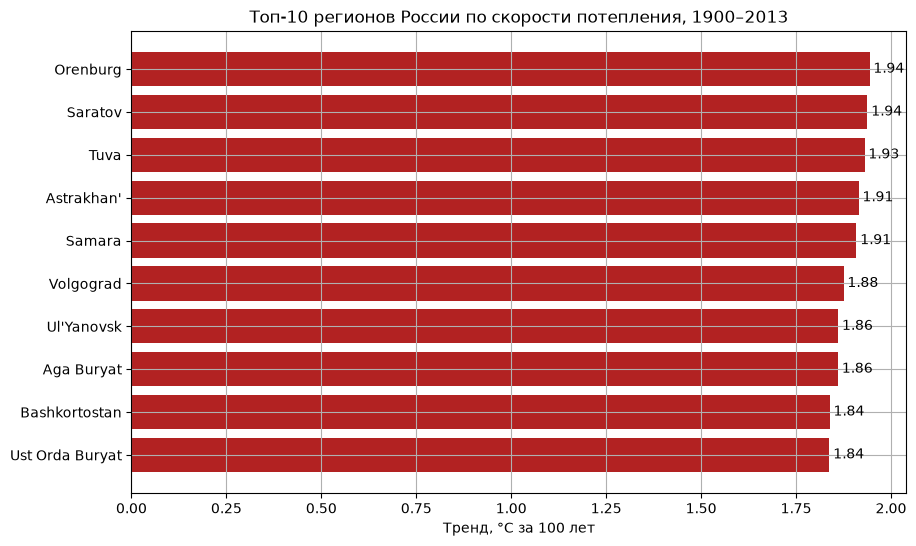

In [5]:
rt = pd.Series({reg: t for (c, reg), t in region_trends.items() if c == 'Russia'}).sort_values(ascending=False)
print(f'Регионов России с оценкой тренда: {len(rt)}')

top10_ru = rt.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10_ru.index, top10_ru.values, color='firebrick')
ax.set_title('Топ-10 регионов России по скорости потепления, 1900–2013')
ax.set_xlabel('Тренд, °C за 100 лет')
for i, v in enumerate(top10_ru.values):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
plt.show()

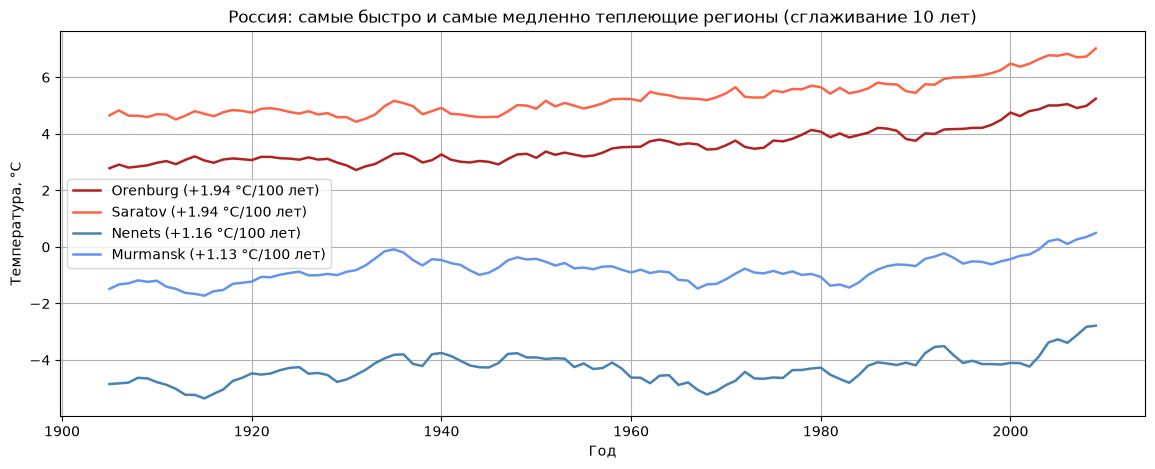

In [6]:
# Динамика двух самых быстро теплеющих и двух самых медленных регионов России
fastest = rt.index[:2].tolist()
slowest = rt.index[-2:].tolist()
ru_ann = st_ann.loc['Russia'].unstack('State')

fig, ax = plt.subplots()
for reg, color in zip(fastest + slowest, ['firebrick', 'tomato', 'steelblue', 'cornflowerblue']):
    s = ru_ann[reg].loc[1900:]
    label = f'{reg} ({rt[reg]:+.2f} °C/100 лет)'
    ax.plot(s.index, s.rolling(10, center=True).mean(), lw=1.8, color=color, label=label)
ax.set_title('Россия: самые быстро и самые медленно теплеющие регионы (сглаживание 10 лет)')
ax.set_xlabel('Год')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

## Выводы

1. Средняя скорость потепления регионов различается по странам почти вдвое: от +0.81 °C/100 лет (Индия) до +1.59 °C/100 лет (Россия) — высокоширотные континентальные страны теплеют быстрее.
2. Внутри России лидируют южные континентальные и сибирские регионы: Оренбургская и Саратовская области (+1.94), Тыва (+1.93 °C/100 лет).
3. Разброс трендов внутри страны велик, поэтому глобальные оценки нельзя напрямую переносить на конкретный регион — для локальных решений нужен анализ именно региональных рядов.